<a href="https://colab.research.google.com/github/NayanChavda96/MDM-Project/blob/main/MDM_Project_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
!pip install -q sentence-transformers google-genai

In [12]:
# SETTINGS AND TOOLS - the only cell where you may want to change a number
import re, json, time, random, difflib, unicodedata, os
from collections import Counter, defaultdict
from datetime import date, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import userdata

# --- How strict should matching be? -------------------------------------------------
SURE_SCORE   = 0.90   # names at least 90% alike  -> same product, no questions asked
UNSURE_SCORE = 0.40   # names less than 40% alike -> different products
                      # anything in between      -> "not sure", the AI helper decides
CODE_MIN     = 0.30   # same product code + names at least 30% alike -> same product
SIZE_MARGIN  = 0.03   # sizes within 3% count as equal (500 ml and 0.5 L)
CHECK_BELOW  = 0.85   # groups which are less than 85% sure about go to the "please check" list

# --- AI helper (Step 6) --------------------------------------------------------------
USE_AI    = True                      # set to False to skip the AI helper
AI_KEY    = userdata.get('Gemini_API_Key')  # Fetches secret value from Secrets panel
AI_MODEL  = "gemini-3.5-flash-lite"   # change this if Google shows a different model name in AI Studio
AI_BATCH  = 40                        # how many pairs we ask about in one go
AI_PAUSE  = 2                         # seconds to wait between asks                        # seconds to wait between asks (keeps us under the free limit)

# --- Your own data (optional) --------------------------------------------------------
USE_MY_OWN_FILE = False               # True = use your own CSV instead of the made-up data
MY_FILE = "my_products.csv"           # needs columns: record_id, source, product_code, product_name, company, size, category, price, active

# --- How tables look ------------------------------------------------------------------
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

def show(table):
    # show a table without the row numbers on the left
    table = table.reset_index(drop=True)
    try:
        display(table.style.hide(axis="index").set_properties(**{"text-align": "left"}))
    except Exception:
        display(table)

def heading(text):
    print("\n" + "=" * 70 + "\n" + text + "\n" + "=" * 70)

print("Ready.")

Ready.


Get Messy Data

In [13]:
# STEP 1a - The real products that exist in the world (you do not need to read this cell)
# Each line: brand, company, category, product type, [flavours / variants], [(size, unit, price), ...]
# A variant written as "Long name|Short name" can also appear in its short form.
real_catalog = [
 ("Head & Shoulders","Procter & Gamble","Hair Care","Shampoo",["Classic Clean","Smooth & Silky|Smooth","Menthol Refresh|Menthol"],[(340,"ml",6.49),(650,"ml",10.99)]),
 ("Pantene","Procter & Gamble","Hair Care","Shampoo",["Pro-V Repair & Protect","Daily Moisture Renewal|Moisture","Smooth & Sleek|Sleek"],[(300,"ml",5.99),(650,"ml",9.49)]),
 ("L'Oréal Paris","L'Oréal","Hair Care","Shampoo",["Total Repair 5","Elvive Color Protect|Color Protect"],[(175,"ml",4.25),(400,"ml",7.25)]),
 ("Dove","Unilever","Hair Care","Shampoo",["Intense Repair","Daily Moisture|Moisture"],[(250,"ml",4.99),(650,"ml",8.99)]),
 ("Johnson's","Kenvue","Baby Care","Baby Shampoo",["No More Tears","Lavender"],[(200,"ml",3.49),(500,"ml",6.49)]),
 ("Pampers","Procter & Gamble","Baby Care","Diapers",["Baby-Dry Size 3|Size 3","Baby-Dry Size 4|Size 4","Swaddlers Size 1|Swaddlers"],[(36,"ct",11.99),(72,"ct",21.99)]),
 ("Dove","Unilever","Personal Care","Body Wash",["Deep Moisture|Deep","Sensitive Skin|Sensitive","Cucumber & Green Tea|Cucumber"],[(295,"ml",4.99),(591,"ml",7.99)]),
 ("Nivea","Beiersdorf","Skin Care","Moisturizing Cream",["Soft","Men Creme|Men"],[(100,"ml",3.99),(200,"ml",5.99)]),
 ("Vaseline","Unilever","Skin Care","Body Lotion",["Intensive Care Cocoa Radiant|Cocoa","Intensive Care Aloe Soothe|Aloe","Healthy Bright|Bright"],[(200,"ml",4.29),(400,"ml",6.29)]),
 ("Neutrogena","Kenvue","Skin Care","Water Gel",["Hydro Boost","Hydro Boost Gel Cream|Gel Cream"],[(50,"g",16.99),(100,"g",24.99)]),
 ("Garnier","L'Oréal","Skin Care","Micellar Cleansing Water",["All-in-1 Classic|Classic","Sensitive Skin|Sensitive","Oil-Infused|Oil"],[(400,"ml",7.99),(700,"ml",11.99)]),
 ("Axe","Unilever","Personal Care","Body Spray",["Dark Temptation|Dark","Africa","Apollo"],[(150,"ml",4.49)]),
 ("Gillette","Procter & Gamble","Personal Care","Razor Blades",["Fusion5 Power|Power","Fusion5 ProGlide|ProGlide"],[(2,"ct",9.99),(4,"ct",17.99),(8,"ct",31.99)]),
 ("Durex","Reckitt","Personal Care","Condoms",["Invisible Extra Thin|Invisible","Extra Safe","Real Feel"],[(3,"ct",4.99),(10,"ct",11.99),(12,"ct",13.99)]),
 ("Colgate","Colgate-Palmolive","Oral Care","Toothpaste",["Total Whitening","Optic White","Max Fresh","Cavity Protection|Cavity"],[(100,"g",2.99),(170,"g",3.99)]),
 ("Sensodyne","Haleon","Oral Care","Toothpaste",["Rapid Relief","Repair & Protect|Repair","Fresh Mint|Mint"],[(75,"ml",5.49),(100,"ml",6.99)]),
 ("Listerine","Kenvue","Oral Care","Mouthwash",["Cool Mint","Total Care","Zero Alcohol|Zero"],[(500,"ml",4.99),(1000,"ml",7.49)]),
 ("Tide","Procter & Gamble","Laundry Care","Liquid Laundry Detergent",["Original","Free & Gentle|Free","Spring Meadow|Meadow"],[(1530,"ml",8.99),(2720,"ml",12.99)]),
 ("Ariel","Procter & Gamble","Laundry Care","Detergent Powder",["Matic Front Load|Front Load","Matic Top Load|Top Load","Sunrise Fresh|Sunrise"],[(1000,"g",7.99),(2000,"g",14.50)]),
 ("Surf Excel","Unilever","Laundry Care","Detergent Powder",["Easy Wash|Easy","Matic Front Load|Front Load"],[(1000,"g",6.99),(2000,"g",12.99)]),
 ("Lysol","Reckitt","Household","Disinfectant Spray",["Crisp Linen|Linen","Lemon Breeze|Lemon","Original Scent|Original"],[(340,"g",4.99),(538,"g",6.99)]),
 ("Dettol","Reckitt","Household","Antiseptic Liquid",["Original","Lavender"],[(250,"ml",3.50),(500,"ml",5.50),(1000,"ml",9.50)]),
 ("Harpic","Reckitt","Household","Toilet Cleaner",["Power Plus Original|Original","Power Plus Lemon|Lemon","Power Plus Pine|Pine"],[(500,"ml",2.99),(1000,"ml",4.99)]),
 ("Clorox","The Clorox Company","Household","Disinfecting Wipes",["Fresh Scent|Fresh","Lemon Fresh|Lemon","Crisp Lemon|Crisp"],[(35,"ct",3.49),(75,"ct",5.79)]),
 ("Febreze","Procter & Gamble","Household","Air Freshener Spray",["Air Effects Linen & Sky|Linen","Air Effects Hawaiian Aloha|Hawaiian"],[(250,"g",3.29),(500,"g",5.49)]),
 ("Bounty","Procter & Gamble","Household","Paper Towels",["Select-A-Size|Select","Quick-Size|Quick"],[(2,"ct",5.99),(6,"ct",14.99)]),
 ("Charmin","Procter & Gamble","Household","Toilet Paper",["Ultra Soft|Soft","Ultra Strong|Strong"],[(6,"ct",8.99),(12,"ct",15.99)]),
 ("Coca-Cola","The Coca-Cola Company","Beverages","Soft Drink",["Original Taste","Zero Sugar|Zero","Cherry"],[(500,"ml",1.79),(2000,"ml",2.99),(12,"ct",8.49)]),
 ("Sprite","The Coca-Cola Company","Beverages","Soft Drink",["Lemon-Lime","Zero Sugar|Zero"],[(500,"ml",1.79),(2000,"ml",2.99)]),
 ("Pepsi","PepsiCo","Beverages","Soft Drink",["Original","Max Zero Sugar|Max","Wild Cherry|Cherry"],[(500,"ml",1.49),(2000,"ml",2.29),(12,"ct",7.99)]),
 ("Mountain Dew","PepsiCo","Beverages","Soft Drink",["Original","Code Red","Baja Blast"],[(500,"ml",1.59),(1250,"ml",1.79)]),
 ("Tropicana","Tropicana Brands","Beverages","Juice",["Pure Premium Orange|Orange","Pure Premium Apple|Apple","Orange No Pulp|No Pulp"],[(450,"ml",2.49),(1530,"ml",4.29)]),
 ("Lipton","Unilever","Beverages","Tea Bags",["Yellow Label|Yellow","Green Tea Citrus|Green","Earl Grey"],[(25,"ct",2.49),(100,"ct",5.99)]),
 ("Gatorade","PepsiCo","Energy & Sports Drinks","Thirst Quencher",["Lemon Lime","Fruit Punch","Cool Blue"],[(591,"ml",1.99),(946,"ml",2.69)]),
 ("Red Bull","Red Bull GmbH","Energy & Sports Drinks","Energy Drink",["Original","Sugarfree","Tropical Edition|Tropical"],[(250,"ml",2.50),(355,"ml",3.29),(473,"ml",3.99)]),
 ("Monster","Monster Beverage","Energy & Sports Drinks","Energy Drink",["Green Original|Green","Ultra White|Ultra","Mango Loco|Mango"],[(473,"ml",2.79),(500,"ml",2.99)]),
 ("Nescafé","Nestlé","Coffee","Instant Coffee",["Gold Blend|Gold","Classic","Decaf"],[(100,"g",5.49),(200,"g",9.99)]),
 ("Heineken","Heineken N.V.","Alcoholic Beverages","Lager Beer",["Original","0.0 Non-Alcoholic|0.0"],[(6,"ct",9.99),(12,"ct",17.99)]),
 ("Lay's","PepsiCo","Snacks","Potato Chips",["Classic","BBQ","Sour Cream & Onion|Sour Cream"],[(40,"g",1.29),(170,"g",3.49),(227,"g",3.99)]),
 ("Doritos","PepsiCo","Snacks","Tortilla Chips",["Nacho Cheese|Nacho","Cool Ranch","Spicy Sweet Chili|Sweet Chili"],[(78,"g",1.99),(262,"g",4.49)]),
 ("Pringles","Kellogg's","Snacks","Potato Crisps",["Original","Sour Cream & Onion|Sour Cream","Cheddar Cheese|Cheddar"],[(40,"g",1.19),(147,"g",2.19),(165,"g",2.49)]),
 ("Oreo","Mondelez International","Snacks","Sandwich Biscuits",["Original","Double Stuf|Double","Golden"],[(120,"g",1.49),(154,"g",2.29),(432,"g",4.49)]),
 ("KitKat","Nestlé","Confectionery","Chocolate Bar",["4 Finger Milk|4 Finger","2 Finger Dark|Dark","Chunky Peanut Butter|Chunky"],[(45,"g",1.29),(160,"g",3.49)]),
 ("Cadbury","Mondelez International","Confectionery","Chocolate Bar",["Dairy Milk Silk|Silk","Dairy Milk Fruit & Nut|Fruit & Nut","Bournville Dark|Bournville"],[(60,"g",1.79),(150,"g",2.99)]),
 ("Ferrero","Ferrero","Packaged Food","Hazelnut Spread",["Nutella Original|Nutella"],[(350,"g",4.49),(750,"g",7.99)]),
 ("Maggi","Nestlé","Packaged Food","Instant Noodles",["2-Minute Masala|Masala","2-Minute Chicken|Chicken","Atta"],[(70,"g",0.75),(280,"g",2.79)]),
 ("Heinz","Kraft Heinz","Packaged Food","Tomato Ketchup",["Original","No Sugar Added|No Sugar"],[(342,"g",2.49),(567,"g",3.49),(1350,"g",5.99)]),
 ("Kraft","Kraft Heinz","Packaged Food","Macaroni & Cheese Dinner",["Original","Three Cheese|Three","White Cheddar|White"],[(206,"g",1.25)]),
 ("Hellmann's","Unilever","Packaged Food","Mayonnaise",["Real","Light"],[(400,"g",3.49),(800,"g",5.99)]),
 ("Quaker","PepsiCo","Breakfast & Cereal","Oats",["Quick 1-Minute|Quick","Old Fashioned|Old","Instant Maple|Maple"],[(510,"g",3.99),(1020,"g",6.49)]),
 ("Kellogg's","Kellogg's","Breakfast & Cereal","Cereal",["Corn Flakes","Frosted Flakes|Frosted","Froot Loops|Froot"],[(300,"g",3.49),(510,"g",4.79)]),
 ("Similac","Abbott","Baby Food","Infant Formula",["Pro-Advance","Sensitive","Total Comfort|Comfort"],[(584,"g",31.99),(850,"g",39.99)]),
]

# How each company's name gets written in different systems.
# The FIRST name in each list is the official one. The data team keeps this list up to date.
company_spellings = {
 "Procter & Gamble":["Procter & Gamble","P&G","P and G","Procter and Gamble Co.","Procter & Gamble Company","PG","Proctor & Gamble"],
 "The Coca-Cola Company":["The Coca-Cola Company","Coca Cola","Coca-Cola Co.","The Coca Cola Co","Coke"],
 "PepsiCo":["PepsiCo","Pepsi Co","Pepsi Co.","PepsiCo Inc.","PEPSICO"],
 "Unilever":["Unilever","Unilevr","Unilever PLC","Unilever Plc","Hindustan Unilever"],
 "Nestlé":["Nestlé","Nestle","Nestle SA","Nestle S.A.","Nestle India"],
 "Colgate-Palmolive":["Colgate-Palmolive","Colgate","Colgate Palmolive","Colgate-Palmolive Co."],
 "Kenvue":["Kenvue","Kenvue Inc.","Johnson & Johnson Consumer","J&J"],
 "Reckitt":["Reckitt","Reckitt Benckiser","RB","Reckitt Benckiser Group","Reckit"],
 "Mondelez International":["Mondelez International","Mondelez","Mondelēz","Cadbury","Mondelez Intl"],
 "Kellogg's":["Kellogg's","Kellogg Company","Kellogg","Kelloggs","Kellanova"],
 "Kraft Heinz":["Kraft Heinz","Kraft","The Kraft Heinz Company","Heinz","KraftHeinz"],
 "L'Oréal":["L'Oréal","L'Oreal","Loreal","L'Oréal Group","LOreal"],
 "The Clorox Company":["The Clorox Company","Clorox","Clorox Co","Clorox Co."],
 "Heineken N.V.":["Heineken N.V.","Heineken","Heineken NV"],
 "Red Bull GmbH":["Red Bull GmbH","Red Bull","RedBull"],
 "Monster Beverage":["Monster Beverage","Monster","Monster Beverage Corp"],
 "Tropicana Brands":["Tropicana Brands","Tropicana","Tropicana Brands Group"],
 "Abbott":["Abbott","Abbott Labs","Abbott Laboratories"],
 "Beiersdorf":["Beiersdorf","Beiersdorf AG","Nivea"],
 "Haleon":["Haleon","GSK","GSK Consumer Healthcare","Haleon plc"],
 "Ferrero":["Ferrero","Ferrero Group","Ferrero SpA"],
}

# How people label the same category differently ("Personal Care" is used loosely by many systems)
category_spellings = {
 "Hair Care":["Hair Care","Haircare","hair care","Hair Care ","Hair & Scalp","Shampoo","Personal Care"],
 "Baby Care":["Baby Care","Baby care","babycare","Baby & Kids","Baby Products"],
 "Baby Food":["Baby Food","Infant Nutrition","Baby Nutrition","baby food"],
 "Personal Care":["Personal Care","Personal care","personal care","Health & Hygiene","Hygiene","Toiletries"],
 "Skin Care":["Skin Care","Skincare","skin care","Skin & Body","Personal Care"],
 "Oral Care":["Oral Care","Oral Hygiene","oral care","Dental","Dental Care"],
 "Laundry Care":["Laundry Care","Laundry","laundry care","Detergents","Household"],
 "Household":["Household","Household Cleaning","Cleaning","Cleaning Supplies","Home Care","Paper Goods","Paper & Plastic","Air Care"],
 "Beverages":["Beverages","Soda","Soft Drinks","Drinks","beverages","Juice","Cold Drinks"],
 "Energy & Sports Drinks":["Energy Drinks","Energy Drink","Sports Drinks","Beverages","Energy & Sports"],
 "Coffee":["Coffee","Hot Beverages","Instant Coffee","Beverages"],
 "Alcoholic Beverages":["Alcoholic Beverages","Beer","Alcohol","Beer & Cider"],
 "Snacks":["Snacks","snacks","Snacks ","Chips & Snacks","Biscuits","Savoury Snacks"],
 "Confectionery":["Confectionery","Sweets","chocolates","Chocolate","Confectionary","Snacks"],
 "Packaged Food":["Packaged Food","Instant Food","Instant Meals","Condiments","Sauces & Condiments","packaged food","Grocery"],
 "Breakfast & Cereal":["Cereal","Breakfast","breakfast food","Breakfast Cereal","Oats & Cereal"],
}

# Nicknames some systems use for brands
brand_nicknames = {
 "Head & Shoulders":["H&S","h & s","Head&Shoulders","Head and Shoulders"], "Coca-Cola":["Coke","Coca Cola","Coca-cola"],
 "Mountain Dew":["Mtn Dew","Mountain Dew","MTN DEW"], "Kellogg's":["Kelloggs","Kellogs","Kellogg"],
 "L'Oréal Paris":["L'Oreal","Loreal","LOreal Paris"], "Johnson's":["Johnsons","Johnson","J&J Baby"],
 "Red Bull":["Redbull","RedBull"], "Nescafé":["Nescafe","NESCAFE"], "Lay's":["Lays","Lay's","LAYS"],
 "KitKat":["Kit Kat","Kitkat","KIT KAT"], "Hellmann's":["Hellmanns","Hellman's"],
 "Pantene":["Pantene Pro-V","Pantine"], "Garnier":["Garnier","Garnir"],
}
extra_words = ["- New!", "| Free Shipping", "(Authentic)", "- Best Seller", "[In Stock]", "- Fast Delivery"]
junk_names  = ["TEST PRODUCT", "sample item", "UNKNOWN ITEM", "xxxx", "do not use"]
yes_words   = ["Active", "TRUE", "1", "Yes", "Y", "active", "True"]
no_words    = ["Inactive", "FALSE", "0", "No", "N", "inactive", "Discontinued"]

print(f"{len(real_catalog)} product families loaded")

52 product families loaded


In [14]:
# STEP 1b - Make the messy data (or load your own file)
rng = random.Random(27)

def pick(options, weights=None):
    return rng.choices(options, weights=weights, k=1)[0]

# How each system likes to write things (numbers are chances, 0.30 = 30% of the time)
systems = {
    "Accounts":     dict(case="title", size_in_name=.65, nickname=.03, typo=.03, short=.10, drop_main=0.00, extra=0.00, swap=.02, code_style="SKU-{n}", code_mix=[.78, .10, .10, .02]),
    "Website":      dict(case="title", size_in_name=.85, nickname=.05, typo=.05, short=.05, drop_main=0.00, extra=.18,  swap=.05, code_style="sku_{n}", code_mix=[.55, .30, .13, .02]),
    "Shop Counter": dict(case="lower", size_in_name=.35, nickname=.40, typo=.10, short=.65, drop_main=.30,  extra=0.00, swap=.08, code_style="{n}",     code_mix=[.45, .15, .38, .02]),
    "Supplier":     dict(case="upper", size_in_name=.90, nickname=.10, typo=.04, short=.15, drop_main=.05,  extra=0.00, swap=.03, code_style="SUP-{n}", code_mix=[.25, .65, .08, .02]),
}

def standard_size_text(amount, unit):
    return {"ml": f"{amount:g} ml", "g": f"{amount:g} g", "ct": f"{amount} ct"}[unit]

def messy_size(amount, unit, category, ptype):
    # the same size written in many different ways
    if unit == "ml":
        options = [f"{amount:g}ml", f"{amount:g} ml", f"{amount:g} ML", f"{amount/1000:g}L", f"{amount/1000:g} l",
                   f"{amount/29.5735:.1f} fl oz", f"{amount/29.5735:.0f}oz", f"{amount:g}", f"{amount/1000:g} liters"]
        weights = [22, 22, 4, 12, 3, 11, 5, 3, 3]
    elif unit == "g":
        options = [f"{amount:g}g", f"{amount:g} g", f"{amount:g} grams", f"{amount/1000:g}kg", f"{amount/28.3495:.1f} oz",
                   f"{amount/28.3495:.2f}oz", f"{amount/453.592:.2f} lb", f"{amount:g}"]
        weights = [26, 22, 8, 6 if amount >= 250 else 0, 12, 4, 3, 3]
    else:
        options = [f"{amount} ct", f"{amount} pack", f"{amount}pk", f"{amount} count", f"{amount} Pack", f"{amount}s"]
        weights = [25, 25, 15, 15, 10, 4]
        if (category == "Beverages" and "Soft" in ptype) or ptype == "Lager Beer":
            options.append(f"{amount} x 355 ml"); weights.append(6)
    return pick(options, weights)

def messy_price(price):
    chance = rng.random()
    if chance < .05: return ""                          # missing
    if chance < .07: return f"-{price:.2f}"             # minus sign by mistake
    if chance < .08: return "N/A"
    if chance < .09: return f"{price*10:.2f}"           # decimal point in the wrong place
    if chance < .10: return "0.00"
    text = f"{price:.2f}"
    return pick([text, f"${text}", text.replace(".", ","), f"USD {text}", f"{text} USD", f"${text} "], [46, 22, 14, 3, 2, 3])

def add_typo(text):
    words = text.split()
    spots = [i for i, w in enumerate(words) if len(w) >= 5 and w.isalpha()]
    if not spots: return text
    i = rng.choice(spots); w = words[i]; k = rng.randrange(1, len(w) - 1)
    how = rng.choice(["drop", "swap", "double"])
    if how == "drop":                      words[i] = w[:k] + w[k+1:]
    elif how == "swap" and k + 2 <= len(w): words[i] = w[:k] + w[k+1] + w[k] + w[k+2:]
    else:                                  words[i] = w[:k] + w[k] + w[k:]
    return " ".join(words)

def messy_name(p, style, size_text):
    brand, variant, ptype = p["brand"], p["variant"], p["type"]
    if rng.random() < style["nickname"] and brand in brand_nicknames: brand = rng.choice(brand_nicknames[brand])
    if p["is_main"]:
        if rng.random() < style["drop_main"]: variant = ""
    elif rng.random() < style["short"]:
        variant = p["short_variant"]
    if rng.random() < .12 and brand not in brands_with_many_types and variant: ptype = ""
    parts = [brand, ptype, variant] if rng.random() < style["swap"] else [brand, variant, ptype]
    name = " ".join(x for x in parts if x)
    if rng.random() < .15: name = name.replace(" & ", " and ")
    if rng.random() < .10: name = re.sub(r"[^\w\s]", "", name)
    if size_text: name += " " + size_text
    if rng.random() < style["extra"]: name += " " + rng.choice(extra_words)
    if rng.random() < style["typo"]: name = add_typo(name)
    if style["case"] == "lower": name = name.lower()
    if style["case"] == "upper": name = name.upper()
    if rng.random() < .06: name = "  " + name + " " if rng.random() < .5 else name.replace(" ", "  ", 1)
    return name

if USE_MY_OWN_FILE:
    data = pd.read_csv(MY_FILE, dtype=str)
    answer_key = None
    real_products = None
    print(f"Loaded your file: {len(data)} rows")
else:
    # 1) list every real product (brand + flavour + size)
    brands_with_many_types = {b for b in {x[0] for x in real_catalog}
                              if len({x[3] for x in real_catalog if x[0] == b}) > 1}
    code_numbers = rng.sample(range(1000, 9999), 5000)
    real_rows = []
    for family_no, (brand, company, category, ptype, variants, sizes) in enumerate(real_catalog, start=1):
        for v_no, v in enumerate(variants):
            long_variant, _, short_variant = v.partition("|")
            for amount, unit, price in sizes:
                real_rows.append(dict(real_product_id=f"REAL-{len(real_rows)+1:04d}", family=family_no, brand=brand, company=company,
                                      category=category, type=ptype, variant=long_variant, short_variant=short_variant or long_variant,
                                      is_main=(v_no == 0), amount=amount, unit=unit, price=price, active=rng.random() > .08,
                                      code_number=code_numbers[len(real_rows)]))

    # 2) every real product appears in 1 to 6 records, each written by a different system
    rows = []
    today = date(2026, 9, 30)
    for p in real_rows:
        how_many = pick([1, 2, 3, 4, 5, 6], [40, 28, 15, 9, 5, 3])
        chosen = rng.sample(list(systems), min(how_many, 4)) + [rng.choice(list(systems)) for _ in range(max(0, how_many - 4))]
        for source in chosen:
            style = systems[source]
            size_blank = rng.random() < .035
            size_in_name = rng.random() < style["size_in_name"] or size_blank      # never blank in both places
            name = messy_name(p, style, messy_size(p["amount"], p["unit"], p["category"], p["type"]) if size_in_name else "")

            spellings = company_spellings[p["company"]]
            company = "" if rng.random() < .04 else pick(spellings, [40] + [60 / (len(spellings) - 1)] * (len(spellings) - 1))
            if company and rng.random() < .12: company = company.lower() if rng.random() < .5 else company.upper()

            spellings = category_spellings[p["category"]]
            category = "" if rng.random() < .04 else pick(spellings, [40] + [60 / (len(spellings) - 1)] * (len(spellings) - 1))

            kind = pick(["shared", "own", "blank", "wrong"], style["code_mix"])
            number = {"shared": p["code_number"], "own": rng.randrange(1000, 99999),
                      "wrong": rng.choice(real_rows)["code_number"], "blank": None}[kind]
            code = "" if number is None else style["code_style"].format(n=number)
            if code and rng.random() < .12: code = code.lower() if rng.random() < .5 else code.replace("-", "_")

            price = round(p["price"] * (rng.uniform(.88, 1.15) if rng.random() < .30 else 1), 2)
            active = p["active"] if rng.random() > .05 else not p["active"]
            age = rng.randrange(5, 250 if source == "Website" else 700)
            rows.append(dict(source=source, product_code=code, product_name=name, company=company,
                             size="" if size_blank else messy_size(p["amount"], p["unit"], p["category"], p["type"]),
                             category=category, price=messy_price(price), active=rng.choice(yes_words if active else no_words),
                             last_updated=(today - timedelta(days=age)).isoformat(), real_product_id=p["real_product_id"]))

    for r in rng.sample(rows, int(.03 * len(rows))): rows.append(dict(r))          # exact copies of some rows
    for k, junk in enumerate(junk_names, start=1):                                  # test / junk rows
        rows.append(dict(source="Shop Counter", product_code="", product_name=junk, company="", size="", category="", price="",
                         active="1", last_updated="2025-01-01", real_product_id=f"JUNK-{k}"))
    rng.shuffle(rows)

    table = pd.DataFrame(rows)
    table.insert(0, "record_id", [f"R{i+1:05d}" for i in range(len(table))])
    table.drop(columns="real_product_id").to_csv("products_messy.csv", index=False)
    table[["record_id", "real_product_id"]].to_csv("answer_key.csv", index=False)
    real_products = pd.DataFrame([dict(real_product_id=p["real_product_id"], family=p["family"],
                                       name=f'{p["brand"]} {p["variant"]} {p["type"]} {standard_size_text(p["amount"], p["unit"])}',
                                       company=p["company"], category=p["category"], size=standard_size_text(p["amount"], p["unit"]),
                                       price=p["price"]) for p in real_rows])
    real_products.to_csv("real_products.csv", index=False)

    # read it back from the file, exactly as you would read any CSV
    data = pd.read_csv("products_messy.csv", dtype=str)
    answer_key = pd.read_csv("answer_key.csv", dtype=str)

# ---- Show what we have ---------------------------------------------------------------------
heading("THE MESSY DATA")
print(f"{len(data)} records (rows).  Here are 12 of them, exactly as the systems wrote them:\n")
columns_to_show = [c for c in ["record_id", "source", "product_code", "product_name", "company", "size", "category", "price", "active"] if c in data.columns]
show(data[columns_to_show].sample(12, random_state=1).fillna("(blank)"))

heading("WHAT IS WRONG WITH THIS DATA?")
price_text = data["price"].fillna("")
problems = pd.DataFrame([
    ("Price is blank or says N/A",                     int(data["price"].isna().sum())),
    ("Price has a $ sign, 'USD' or a comma for a dot", int(price_text.str.contains(r"\$|USD|,", regex=True).sum())),
    ("Price is negative",                              int(price_text.str.strip().str.startswith("-").sum())),
    ("Company name is blank",                          int(data["company"].isna().sum())),
    ("Category is blank",                              int(data["category"].isna().sum())),
    ("Product code is blank",                          int(data["product_code"].isna().sum())),
    ("Size is blank",                                  int(data["size"].isna().sum())),
    ("Different ways the company name is written",     int(data["company"].dropna().nunique())),
    ("Different ways the category is written",         int(data["category"].dropna().nunique())),
    ("Different ways the size is written",             int(data["size"].dropna().nunique())),
    ("Rows that are exact copies of another row",      int(data.drop(columns=["record_id"]).duplicated().sum())),
], columns=["Problem", "How many"])
show(problems)

if "source" in data.columns:
    print("\nRecords per system:   " + "   |   ".join(f"{name}: {int(n)}" for name, n in data["source"].value_counts().items()))
if answer_key is not None:
    print(f"\nThe answer key says these {len(data)} records are really {answer_key['real_product_id'].nunique()} different things "
          f"({real_products.shape[0]} real products + {answer_key['real_product_id'].str.startswith('JUNK').sum()} junk rows).")
    print("We will use it only at the end, to check our work.")


THE MESSY DATA
716 records (rows).  Here are 12 of them, exactly as the systems wrote them:



record_id,source,product_code,product_name,company,size,category,price,active
R00060,Website,sku_5060,L'Oréal Paris Shampoo Total Rpair 5 0.4L,L'Oréal Group,0.4 liters,Hair Care,$7.25,active
R00061,Shop Counter,(blank),sensodyne mint toothpaste,Haleon,100ml,Oral Care,6.99,active
R00384,Accounts,sku-6208,Charmin Ultra Strong Toilet Paper 12pk,(blank),12s,Home Care,(blank),active
R00160,Shop Counter,(blank),nescafe decaf instant coffee,Nestle India,100,Instant Coffee,5.49,1
R00009,Supplier,SUP-3067,COCA-COLA ORIGINAL TASTE SOFT DRINK 12 COUNT,The Coca-Cola Company,12 pack,Drinks,8.16,Y
R00102,Accounts,SKU-35176,Dove Cucumber & Green Tea Body Wash 0.591 liters,Unilevr,20.0 fl oz,Personal care,"7,99",Yes
R00287,Shop Counter,7286,surf excel matic front load detergent powder,Unilever,2000 g,Laundry Care,12.99,Active
R00258,Shop Counter,2028,lysol disinfectant spray crisp linen,Reckit,340 g,Paper & Plastic,4.99 USD,True
R00580,Accounts,SKU-9047,L'Oréal Paris Elvive Color Protect Shampoo,L'Oreal,13.5 fl oz,hair care,8.20,active
R00202,Accounts,SKU_4960,Sprite Zero Sugar 2000ml,The Coca-Cola Company,2000 ml,Beverages,"2,99",active



WHAT IS WRONG WITH THIS DATA?


Problem,How many
Price is blank or says N/A,44
"Price has a $ sign, 'USD' or a comma for a dot",321
Price is negative,15
Company name is blank,34
Category is blank,29
Product code is blank,118
Size is blank,29
Different ways the company name is written,138
Different ways the category is written,80
Different ways the size is written,305



Records per system:   Supplier: 188   |   Accounts: 188   |   Shop Counter: 175   |   Website: 165

The answer key says these 716 records are really 306 different things (301 real products + 5 junk rows).
We will use it only at the end, to check our work.


## Step 2: What is the problem in the Data ?

Below is **one real product** that the 4 systems have written down many times.
All of these rows are the same product, but a computer comparing the text would think they are different.

In [15]:
# STEP 2 - One product, written many different ways
if answer_key is None:
    print("Skipped: this step uses the answer key, and your own file does not have one.")
else:
    joined = data.merge(answer_key, on="record_id")
    many = joined[~joined["real_product_id"].str.startswith("JUNK")]["real_product_id"].value_counts()
    example_id = many.index[0]
    example_name = real_products.set_index("real_product_id").at[example_id, "name"]

    heading(f"EXAMPLE 1: all these rows are ONE product  ->  {example_name}")
    show(joined[joined["real_product_id"] == example_id][["source", "product_name", "company", "size", "category", "price", "product_code"]].fillna("(blank)"))

    # the company with the most different spellings
    with_company = joined.merge(real_products[["real_product_id", "company"]], on="real_product_id", suffixes=("_written", "_real"))
    spelling_counts = with_company.groupby("company_real")["company_written"].nunique().sort_values(ascending=False)
    biggest = spelling_counts.index[0]
    written = with_company[with_company["company_real"] == biggest]["company_written"].fillna("(blank)").value_counts()
    heading(f"EXAMPLE 2: one company, written {len(written)} different ways  ->  {biggest}")
    show(written.rename_axis("How it was written").reset_index(name="Number of rows"))


EXAMPLE 1: all these rows are ONE product  ->  Sensodyne Repair & Protect Toothpaste 75 ml


source,product_name,company,size,category,price,product_code
Supplier,SENSODYNE REPAIR & PROTECT TOOTHPASTE 75 ML,haleon plc,75,Oral Care,5.49,SUP-80555
Shop Counter,sensodyne repair & protect toothpaste,GSK,75 ML,Oral Hygiene,5.49,(blank)
Accounts,Sensodyne Repair & Protect Toothpaste 0.075L,Haleon,0.075L,Oral Hygiene,"5,49",SKU-1368
Supplier,SENSODYNE REPAIR & PROTECT TOOTHPASTE 75ML,GSK Consumer Healthcare,75ml,Dental,5.61,SUP-73906
Shop Counter,sensodyne repair toothpaste,Haleon,0.075L,Oral Care,"5,49",1368
Accounts,Sensodyne Repair & Protect Toothpaste 0.075L,Haleon,0.075L,Oral Hygiene,"5,49",SKU-1368
Website,Sensodyne Repaair and Protect Toothpaste (Authentic),GSK Consumer Healthcare,75 ml,Dental,5.49,sku_66516



EXAMPLE 2: one company, written 13 different ways  ->  Procter & Gamble


How it was written,Number of rows
Procter & Gamble,36
Procter and Gamble Co.,15
Procter & Gamble Company,11
P and G,11
P&G,10
PG,10
Proctor & Gamble,9
PROCTER & GAMBLE,6
(blank),4
procter & gamble,3


## Step 3: Clean the columns

Before comparing products, we fix everything we can fix with **simple fixed rules**. No AI is used here.
Rules are fast, free and always give the same answer.

- **Company**: `P&G`, `Procter and Gamble Co.`, `Proctor & Gamble` all become `Procter & Gamble`
- **Category**: `Haircare`, `hair care`, `Hair & Scalp` all become `Hair Care`
- **Price**: `$6.49`, `6,49`, `USD 6.49`, `-6.49` all become the number `6.49`
- **Size**: `0.5L`, `500ml`, `16.9 fl oz` all become `500 ml`
- **Product code**: `sku_1234`, `SUP-1234`, `1234` all become `CODE-1234`
- **Name**: lower case, no size, no punctuation, and nicknames expanded (`coke` becomes `coca cola`) so that names can be compared fairly


In [16]:
# STEP 3a - The rules the data team keeps (edit these when you meet a new spelling)

# Category rules: if the text contains these words, use this category. The most specific rules come first.
category_rules = [
    (r"infant|baby ?nutrition|baby ?food", "Baby Food"), (r"baby", "Baby Care"), (r"hair|shampoo", "Hair Care"),
    (r"skin", "Skin Care"), (r"oral|dental", "Oral Care"), (r"laundry|detergent", "Laundry Care"),
    (r"coffee|hot bev", "Coffee"), (r"energy|sport", "Energy & Sports Drinks"), (r"beer|alcohol", "Alcoholic Beverages"),
    (r"soda|soft drink|juice|beverage|drinks", "Beverages"), (r"confection|sweet|chocolate", "Confectionery"),
    (r"snack|chips|biscuit", "Snacks"), (r"cereal|breakfast|oats", "Breakfast & Cereal"),
    (r"packaged|instant|condiment|sauce|grocery", "Packaged Food"), (r"household|clean|air care|paper|home care", "Household"),
    (r"hygiene|personal|toiletries|shaving|health", "Personal Care"),
]

# Nicknames that are replaced before names are compared
nickname_rules = {r"\bh and s\b": "head and shoulders", r"\bh&s\b": "head and shoulders", r"\bmtn\b": "mountain",
                  r"\bcoke\b": "coca cola", r"\bredbull\b": "red bull"}

# Units: how many ml / grams is one of each unit?
liquid_units = {"ml": 1, "l": 1000, "liter": 1000, "liters": 1000, "litre": 1000, "litres": 1000, "floz": 29.5735}
weight_units = {"g": 1, "gram": 1, "grams": 1, "kg": 1000, "lb": 453.592, "lbs": 453.592}
count_units  = {"ct", "count", "pack", "pk", "roll", "rolls", "wipe", "wipes", "s"}
liquid_words = r"gatorade|juice|soda|drink|cola|pepsi|water|shampoo|wash|detergent|lotion|mouthwash|liquid|beer|sprite|dew|tea"
# Finds a size that is written inside a product name, e.g. "Dettol Lavender 250 ml" -> "250 ml"
size_in_name_pattern = re.compile(r"\b(\d+(?:\.\d+)?\s*(?:x\s*\d+(?:\.\d+)?\s*)?(?:fl\s*oz|oz|ml|l|liters?|litres?|g|kg|grams?|lbs?|ct|pk|pack|count|s))\b", re.I)
print("Rules loaded.")

Rules loaded.


In [17]:
# STEP 3b - Clean every column
def letters_only(text):
    text = unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9]", "", text)

company_lookup = {letters_only(spelling): official for official, spellings in company_spellings.items() for spelling in spellings}

def fix_company(x):
    if pd.isna(x): return None
    key = letters_only(x)
    if key in company_lookup: return company_lookup[key]
    close = difflib.get_close_matches(key, company_lookup.keys(), n=1, cutoff=0.85)      # catches small spelling mistakes
    return company_lookup[close[0]] if close else str(x).strip().title()

def fix_category(x):
    if pd.isna(x): return None
    text = str(x).lower().strip()
    for words, category in category_rules:
        if re.search(words, text): return category
    return str(x).strip().title()

def fix_code(x):
    found = re.search(r"(\d{3,})", str(x)) if not pd.isna(x) else None
    return f"CODE-{found.group(1)}" if found else ""

def fix_active(x):
    return str(x).strip().lower() in {"true", "1", "yes", "y", "active"}

def fix_price(x):
    # returns (price as a number, a note about what we had to fix)
    if pd.isna(x): return None, "price missing"
    text = str(x).strip().replace("$", "").replace("USD", "").replace("usd", "").strip()
    note = ""
    if text.startswith("-"):
        text, note = text[1:], "minus sign removed from price"
    if re.fullmatch(r"\d+,\d{2}", text):
        text, note = text.replace(",", "."), "comma in price changed to dot"
    try:
        return float(text), note
    except ValueError:
        return None, "price could not be read"

def read_size(text):
    # returns the possible meanings of a size, e.g. [("volume", 500)] = 500 ml, [("weight", 340)] = 340 g, [("count", 12)] = 12 pieces
    if pd.isna(text): return []
    s = str(text).lower().strip()
    if s == "": return []
    found = re.fullmatch(r"(\d+)\s*x\s*[\d.]+\s*(?:fl\s*oz|oz|ml|l|g)", s)             # "12 x 355 ml" = 12 pieces
    if found: return [("count", float(found[1]))]
    found = re.fullmatch(r"([\d.]+)\s*(fl\s*oz|oz|ml|liters?|litres?|l|kg|grams?|g|lbs?|ct|count|pack|pk|rolls?|wipes?|s)?", s)
    if not found: return []
    number, unit = float(found[1]), (found[2] or "").replace(" ", "")
    if unit in liquid_units: return [("volume", number * liquid_units[unit])]
    if unit in weight_units: return [("weight", number * weight_units[unit])]
    if unit in count_units:  return [("count", number)]
    if unit == "oz": return [("weight", number * 28.3495), ("volume", number * 29.5735)]    # "oz" could be either
    return [("weight", number), ("volume", number)]                                       # a bare number: unit unknown

def size_text(kind, amount):
    return {"volume": f"{round(amount)} ml", "weight": f"{round(amount)} g", "count": f"{int(amount)} ct"}[kind]

def sizes_match(a, b):
    if not a or not b: return True                         # unknown size: we cannot rule it out
    return any(ka == kb and abs(va - vb) <= SIZE_MARGIN * max(va, vb) for ka, va in a for kb, vb in b)

def simplify_name(name, expand_nicknames=True):
    text = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode().lower().replace("&", " and ")
    text = text.replace("'", "")                                                                 # Lay's and Lays look the same
    if expand_nicknames:
        for old, new in nickname_rules.items(): text = re.sub(old, new, text)
    text = re.sub(r"\d+(\.\d+)?\s*(fl\s*oz|oz|ml|l|liters?|litres?|grams?|g|kg|lbs?|ct|pk|pack|count|s)\b", " ", text)    # remove the size
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", text)).strip()

def size_after(options):
    if len(options) == 1: return size_text(*options[0])
    return "unit unclear" if options else None

def style_of(text):
    # "500ml" and "250 ml" have the same style: a number followed by ml
    return re.sub(r"\d+(\.\d+)?", "#", str(text).lower().strip())

# ---- apply every rule to every row -----------------------------------------------------------
prices = data["price"].map(fix_price)
clean = pd.DataFrame({
    "record_id":    data["record_id"],
    "source":       data["source"] if "source" in data.columns else "Unknown",
    "code":         data["product_code"].map(fix_code),
    "company":      data["company"].map(fix_company),
    "category":     data["category"].map(fix_category),
    "size_options": [read_size(x) for x in data["size"]],
    "price":        prices.map(lambda t: t[0]),
    "active":       data["active"].map(fix_active),
    "name_simple":  data["product_name"].map(simplify_name),
})
notes = [[t[1]] if t[1] else [] for t in prices]
for i in range(len(clean)):
    if clean.at[i, "code"] == "": notes[i].append("code missing")
    if not clean.at[i, "size_options"]:                        # size column is blank: look inside the product name
        in_name = size_in_name_pattern.findall(str(data.at[i, "product_name"]))
        if in_name:
            clean.at[i, "size_options"] = read_size(in_name[-1])
            notes[i].append("size was blank, read it from the product name")
        else:
            notes[i].append("size missing")
clean["size_nice"] = clean["size_options"].map(size_after)
clean["notes"] = notes

# ---- show before and after ---------------------------------------------------------------------
sample = clean.sample(10, random_state=4).index
heading("BEFORE  ->  AFTER  (company and category)")
show(pd.DataFrame({"Company (before)": data.loc[sample, "company"], "Company (after)": clean.loc[sample, "company"],
                   "Category (before)": data.loc[sample, "category"], "Category (after)": clean.loc[sample, "category"]}).fillna("(blank)"))

heading("BEFORE  ->  AFTER  (price, size, code)")
show(pd.DataFrame({"Price (before)": data.loc[sample, "price"], "Price (after)": clean.loc[sample, "price"],
                   "Size (before)": data.loc[sample, "size"], "Size (after)": clean.loc[sample, "size_nice"],
                   "Code (before)": data.loc[sample, "product_code"], "Code (after)": clean.loc[sample, "code"]}).fillna("(blank)"))

heading("BEFORE  ->  AFTER  (product name, used for comparing)")
show(pd.DataFrame({"Name (before)": data.loc[sample, "product_name"].str.strip(), "Name (after)": clean.loc[sample, "name_simple"]}))

heading("CLEAN-UP SCOREBOARD")
plain_price = data["price"].fillna("").str.fullmatch(r"\d+\.\d+")
show(pd.DataFrame([
    ("Different company spellings",         data["company"].dropna().nunique(),                    clean["company"].dropna().nunique()),
    ("Different category labels",           data["category"].dropna().nunique(),                   clean["category"].dropna().nunique()),
    ("Different styles of writing a size",  data["size"].dropna().map(style_of).nunique(),         clean["size_nice"].dropna().map(style_of).nunique()),
    ("Different styles of product code",    data["product_code"].dropna().map(style_of).nunique(), clean.loc[clean["code"] != "", "code"].map(style_of).nunique()),
    ("Rows with a price that is a plain number", int(plain_price.sum()),                           int(clean["price"].notna().sum())),
], columns=["", "Before", "After"]))

fixes = Counter(n for row in clean["notes"] for n in row)
print("\nProblems found while cleaning (these rows are marked so nobody is misled):")
show(pd.DataFrame(sorted(fixes.items(), key=lambda kv: -kv[1]), columns=["What we found", "Number of rows"]))


BEFORE  ->  AFTER  (company and category)


Company (before),Company (after),Category (before),Category (after)
(blank),(blank),Home Care,Household
Red Bull GmbH,Red Bull GmbH,Energy Drinks,Energy & Sports Drinks
clorox co,The Clorox Company,Household Cleaning,Household
Unilever PLC,Unilever,Condiments,Packaged Food
Unilevr,Unilever,Instant Food,Packaged Food
Pepsi Co,PepsiCo,Cold Drinks,Beverages
Tropicana,Tropicana Brands,Soft Drinks,Beverages
PepsiCo Inc.,PepsiCo,Chips & Snacks,Snacks
Reckit,Reckitt,Paper Goods,Household
PEPSICO,PepsiCo,Biscuits,Snacks



BEFORE  ->  AFTER  (price, size, code)


Price (before),Price (after),Size (before),Size (after),Code (before),Code (after)
(blank),(blank),12s,12 ct,sku-6208,CODE-6208
USD 3.99,3.990000,473 ml,473 ml,sku_29408,CODE-29408
$6.23,6.230000,75 ct,75 ct,SKU-5980,CODE-5980
-3.49,3.490000,400g,400 g,SKU-4278,CODE-4278
"6,83",6.830000,800 g,800 g,SKU-5599,CODE-5599
-1.79,1.790000,1250 ml,1250 ml,sku_9232,CODE-9232
$2.24,2.240000,450 ml,450 ml,4942,CODE-4942
4.13,4.130000,227 g,227 g,(blank),
(blank),(blank),500ml,500 ml,4813,CODE-4813
$3.49,3.490000,170g,170 g,sku_9005,CODE-9005



BEFORE  ->  AFTER  (product name, used for comparing)


Name (before),Name (after)
Charmin Ultra Strong Toilet Paper 12pk,charmin ultra strong toilet paper
RedBull Tropical Edition Energy Drink 0.473L,red bull tropical edition energy drink
Clorox Crisp Lemon Disinfecting Wipes 75 count,clorox crisp lemon disinfecting wipes
Hellmann's Light Mayonnaise 400g,hellmanns light mayonnaise
Hellmann's Real 1.76 lb,hellmanns real
Mountain Dew Original Soft Drink 1250ml,mountain dew original soft drink
tropicana apple juice,tropicana apple juice
lay's classic 227g,lays classic
dettol original antiseptic liquid 0.5 l,dettol original antiseptic liquid
Lay's Classic Potato Chips 170 grams,lays classic potato chips



CLEAN-UP SCOREBOARD


,Before,After
Different company spellings,138,21
Different category labels,80,16
Different styles of writing a size,19,4
Different styles of product code,5,1
Rows with a price that is a plain number,336,672



Problems found while cleaning (these rows are marked so nobody is misled):


What we found,Number of rows
code missing,118
comma in price changed to dot,113
price missing,44
"size was blank, read it from the product name",23
minus sign removed from price,15
size missing,6


## Step 4: Turn product names into numbers (embeddings)

Computers cannot "read" a name, but they can compare numbers.
So we use a small language model (**MiniLM**) that turns every product name into a list of numbers that captures its *meaning*.
Names that mean the same thing end up with similar numbers.

Then we measure how close two names are and give a **similarity score from 0% to 100%**:

- `coke zero 500ml` vs `Coca-Cola Zero Sugar 500 ml` → high score (same product)
- `Coca-Cola Zero Sugar` vs `Coca-Cola Cherry` → medium score (same brand, **different** product)
- `Coca-Cola Zero Sugar` vs `Dettol Lavender` → low score (nothing in common)

If MiniLM cannot be loaded, the notebook automatically uses a simpler letter-matching method so it still runs.

In [18]:
# STEP 4 - Names -> numbers -> similarity score
def names_to_numbers(names):
    try:
        from sentence_transformers import SentenceTransformer
        model = SentenceTransformer("all-MiniLM-L6-v2")
        print("Using the MiniLM language model to read the names.")
        return model.encode(names, normalize_embeddings=True, show_progress_bar=False)
    except Exception as problem:
        print(f"MiniLM could not be loaded ({type(problem).__name__}), so we use the simpler letter-matching method instead.")
        from sklearn.feature_extraction.text import TfidfVectorizer
        return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4)).fit_transform(names).toarray()

name_numbers = names_to_numbers(clean["name_simple"].tolist())
name_similarity = np.clip(name_numbers @ name_numbers.T, 0, 1)       # one score for every pair of records
print(f"Each of the {len(clean)} names is now a list of {name_numbers.shape[1]} numbers.")

# ---- A small demo: how alike are some names? ----------------------------------------------------
if answer_key is not None:
    heading("DEMO: SIMILARITY SCORES FOR SOME PAIRS OF NAMES")
    real_id = answer_key["real_product_id"].values
    family_of = real_products.set_index("real_product_id")["family"].to_dict()
    size_of = real_products.set_index("real_product_id")["size"].to_dict()
    in_example = np.where(real_id == example_id)[0]
    a = in_example[0]
    pairs_to_show = [("Same product", a, in_example[1]), ("Same product", a, in_example[-1])]
    # same brand, different product (a look-alike)
    for j in range(len(clean)):
        r = real_id[j]
        if r != example_id and not r.startswith("JUNK") and family_of.get(r) == family_of[example_id] and size_of[r] == size_of[example_id]:
            pairs_to_show.append(("Look-alike, DIFFERENT product", a, j)); break
    # nothing in common
    for j in range(len(clean)):
        r = real_id[j]
        if not r.startswith("JUNK") and family_of.get(r) != family_of[example_id]:
            pairs_to_show.append(("Completely different", a, j)); break
    show(pd.DataFrame([(truth, data.at[i, "product_name"].strip(), data.at[j, "product_name"].strip(), f"{name_similarity[i, j]:.0%}")
                       for truth, i, j in pairs_to_show], columns=["What they really are", "Name 1", "Name 2", "Similarity score"]))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Using the MiniLM language model to read the names.
Each of the 716 names is now a list of 384 numbers.

DEMO: SIMILARITY SCORES FOR SOME PAIRS OF NAMES


What they really are,Name 1,Name 2,Similarity score
Same product,SENSODYNE REPAIR & PROTECT TOOTHPASTE 75 ML,sensodyne repair & protect toothpaste,100%
Same product,SENSODYNE REPAIR & PROTECT TOOTHPASTE 75 ML,Sensodyne Repaair and Protect Toothpaste (Authentic),82%
"Look-alike, DIFFERENT product",SENSODYNE REPAIR & PROTECT TOOTHPASTE 75 ML,Sensodyne Fresh Mint Toothpaste 0.075 liters,80%
Completely different,SENSODYNE REPAIR & PROTECT TOOTHPASTE 75 ML,CADBURY BOURNVILLE CHOCOLATE BAR 60 G,11%


## Step 5: Find possible matches

Now we compare **every record with every other record** and sort each pair into one of three boxes:

| Box | Rule | What happens |
|---|---|---|
| **Sure: same product** | Names are 90% alike or more, **or** same product code with fairly alike names | Merged automatically |
| **Not sure** | Names are 40% to 90% alike | Sent to the AI helper (Step 6) |
| **Different** | Names are less than 40% alike | Ignored |

One extra rule: **two records with different sizes can never match** (a 500 ml bottle and a 2 L bottle are different products).
If a size is blank we cannot rule the pair out, so it stays in the race.

In [19]:
# STEP 5 - Compare every pair of records and sort them into boxes
count = len(clean)
size_options = clean["size_options"].tolist()
codes = clean["code"].tolist()

found = []                 # pairs that are "sure" or "not sure"
ruled_out_by_size = 0
for i in range(count):
    for j in range(i + 1, count):
        if not sizes_match(size_options[i], size_options[j]):
            ruled_out_by_size += 1
            continue
        score = float(name_similarity[i, j])
        same_code = codes[i] != "" and codes[i] == codes[j]
        if score >= SURE_SCORE:                   found.append((i, j, score, "sure",   "names almost identical"))
        elif same_code and score >= CODE_MIN:     found.append((i, j, score, "sure",   "same product code"))
        elif score >= UNSURE_SCORE:               found.append((i, j, score, "unsure", ""))

pairs = pd.DataFrame(found, columns=["first", "second", "score", "box", "how"])
sure_pairs = pairs[pairs["box"] == "sure"].reset_index(drop=True)
unsure_pairs = pairs[pairs["box"] == "unsure"].sort_values("score", ascending=False).reset_index(drop=True)
total_pairs = count * (count - 1) // 2

heading("HOW THE PAIRS WERE SORTED")
show(pd.DataFrame([
    ("All possible pairs of records",                 f"{total_pairs:,}"),
    ("Ruled out: the sizes are different",            f"{ruled_out_by_size:,}"),
    ("Ruled out: the names are clearly different",    f"{total_pairs - ruled_out_by_size - len(pairs):,}"),
    ("SURE: same product",                            f"{len(sure_pairs):,}"),
    ("NOT SURE: needs a second opinion",              f"{len(unsure_pairs):,}"),
], columns=["Box", "Number of pairs"]))

def pair_examples(table, how_many, label):
    rows = table.sample(min(how_many, len(table)), random_state=2)
    return pd.DataFrame({"Box": label, "Name 1": [data.at[i, "product_name"].strip() for i in rows["first"]],
                         "Name 2": [data.at[j, "product_name"].strip() for j in rows["second"]],
                         "Similarity": [f"{s:.0%}" for s in rows["score"]]})

heading("EXAMPLES")
show(pd.concat([pair_examples(sure_pairs, 5, "Sure: same product"), pair_examples(unsure_pairs, 6, "Not sure")]))


HOW THE PAIRS WERE SORTED


Box,Number of pairs
All possible pairs of records,"255,970"
Ruled out: the sizes are different,"245,869"
Ruled out: the names are clearly different,"7,188"
SURE: same product,658
NOT SURE: needs a second opinion,"2,255"



EXAMPLES


Box,Name 1,Name 2,Similarity
Sure: same product,Mountain Dew Code Red Soft Drink 0.5L (Authentic),MOUNTAIN DEW CODE RED SOFT DRINK 500 ML,89%
Sure: same product,nescafé classic instant coffee 100 grams,Nescafé Classic Instant Coffee 100g,100%
Sure: same product,tide liquid laundry detergent,TIDE ORIGINAL LIQUID LAUNDRY DETERGENT 1.53L,94%
Sure: same product,Nescafé Decaf Instant Coffee 100g,NESCAFÉ DECAF INSTANT COFFEE 100G,100%
Sure: same product,Neutrogena Hydro Boost Water Gel,neutrogena hydro boost gel cream water gel 3.53oz,96%
Not sure,mountain dew original soft dink 500ml,MOUNTAIN DEW CODE RED SOFT DRINK 500 ML,62%
Not sure,CLOROX CRISP LEMON DISINFECTING WIPES 35 COUNT,Clorox Fresh Scent 35pk,51%
Not sure,Pringles Original Potato Crisps,Pringles Sour Cream Onion Potato Crisps 5.2 oz,85%
Not sure,Sprite Lemon-Lime Soft Drink,sprite lemonlime soft drink 500 ml,89%
Not sure,Mountain Dew Baja Blast Soft Drink,COCA-COLA CHERRY SOFT DRINK 500 ML,59%


## Step 6: Ask the AI helper about the "not sure" pairs (optional)

For the pairs in the *not sure* box, a rule cannot decide. For example, are
`Dove Daily Moisture Shampoo 250 ml` and `Dove Intense Repair Shampoo 250 ml` the same product? *(No: different flavour.)*

This is where an AI model (**Google Gemini**) helps. We show it the two records and ask one question:
**"Are these the same sellable product?"** It answers yes or no, with a reason.

Important rules of this notebook:
- The AI **only judges pairs**. It never cleans data and never makes up IDs. Rules do all the cleaning.
- The AI sees **only the not-sure pairs**, so it stays cheap and fast.

**To switch it on (free):** get a key from [Google AI Studio](https://aistudio.google.com/apikey), then click the key icon on the left side of Colab,
add a secret named `GEMINI_API_KEY`, and switch "Notebook access" on. (Or paste the key into `AI_KEY` in the settings cell.)
**No key? No problem:** the notebook continues without the AI, and the not-sure pairs simply stay separate.

In [23]:
# STEP 6 - Ask the AI helper (Gemini) about the "not sure" pairs
from pydantic import BaseModel

class Answer(BaseModel):            # the shape of the answer we ask the AI to give
    pair_number: int
    same_product: bool
    sure: float                     # how sure the AI is, from 0 to 1
    reason: str

def find_key():
    if AI_KEY: return AI_KEY
    try:
        from google.colab import userdata
        return userdata.get("GEMINI_API_KEY")
    except Exception:
        return os.environ.get("GEMINI_API_KEY")

def describe_record(i):
    def text(column):
        value = data.at[i, column] if column in data.columns else None
        return "" if pd.isna(value) else str(value).strip()
    return {"name": text("product_name"), "company": text("company"), "size": text("size"), "price": text("price")}

def ask_ai(pair_table, key):
    from google import genai
    from google.genai import types
    client = genai.Client(api_key=key)
    answers, in_a_row_failed = {}, 0
    for start in range(0, len(pair_table), AI_BATCH):
        chunk = pair_table.iloc[start:start + AI_BATCH]
        questions = [dict(pair_number=int(n), similarity=round(float(r['score']), 2), record_A=describe_record(r['first']), record_B=describe_record(r['second']))
             for n, r in chunk.iterrows()]
        prompt = ("You are a careful data steward. For each pair decide if both records describe the SAME sellable product "
                  "(same brand, product line, flavour/variant and pack size). Different flavours or variants (Zero vs Original, "
                  "Optic White vs Total Whitening) and different sizes are DIFFERENT products. Spelling mistakes, capital letters, "
                  "brand nicknames and the way sizes are written are NOT differences. Give one answer per pair_number.\n\n"
                  + json.dumps(questions, indent=1))
        worked = False
        for attempt in range(3):
            try:
                reply = client.models.generate_content(model=AI_MODEL, contents=prompt,
                            config=types.GenerateContentConfig(response_mime_type="application/json", response_schema=list[Answer], temperature=0.0))
                for a in (reply.parsed or [Answer(**x) for x in json.loads(reply.text)]):
                    answers[a.pair_number] = a
                worked = True
                break
            except Exception as problem:
                last_problem = problem
                time.sleep(3 * (attempt + 1))
        in_a_row_failed = 0 if worked else in_a_row_failed + 1
        if in_a_row_failed >= 2:
            print(f"\nThe AI helper is not answering, so we stop here. The reason it gave: {str(last_problem)[:200]}")
            print("Check the key and the AI_MODEL name in the settings cell. The notebook continues without the missing answers.")
            break
        print(f"  asked about {min(start + AI_BATCH, len(pair_table))} of {len(pair_table)} pairs", end="\r")
        time.sleep(AI_PAUSE)
    print()
    return answers

ai_ran = False
ai_answers = pd.DataFrame(columns=["first", "second", "same_product", "sure", "reason"])
key = find_key() if USE_AI else None

if not USE_AI:
    print("The AI helper is switched off (USE_AI = False). The 'not sure' pairs stay separate and are flagged for a human to check.")
elif not key:
    print("No Gemini key found, so the AI helper is skipped. The 'not sure' pairs stay separate and are flagged for a human to check.")
    print("To switch it on: add a secret named GEMINI_API_KEY (key icon on the left), then run this cell again.")
elif len(unsure_pairs) == 0:
    print("There are no 'not sure' pairs, so the AI helper is not needed.")
else:
    print(f"Asking the AI helper about {len(unsure_pairs)} pairs ...")
    replies = ask_ai(unsure_pairs, key)
    ai_ran = len(replies) > 0
    ai_answers = pd.DataFrame([dict(first=int(unsure_pairs.at[n, "first"]), second=int(unsure_pairs.at[n, "second"]), same_product=a.same_product,
                                    sure=a.sure, reason=a.reason) for n, a in replies.items()])

if ai_ran:
    heading("WHAT THE AI HELPER SAID")
    said_same = int(ai_answers["same_product"].sum())
    show(pd.DataFrame([("Same product (merge them)", said_same), ("Different products (keep apart)", len(ai_answers) - said_same),
                       ("No answer received", len(unsure_pairs) - len(ai_answers))], columns=["AI answer", "Number of pairs"]))
    nice = pd.DataFrame({"Name 1": [data.at[i, "product_name"].strip() for i in ai_answers["first"]],
                         "Name 2": [data.at[j, "product_name"].strip() for j in ai_answers["second"]],
                         "AI says": ai_answers["same_product"].map({True: "SAME", False: "DIFFERENT"}),
                         "Why": ai_answers["reason"]})
    show(pd.concat([nice[nice["AI says"] == "SAME"].head(4), nice[nice["AI says"] == "DIFFERENT"].head(4)]))

Asking the AI helper about 2255 pairs ...


WHAT THE AI HELPER SAID


AI answer,Number of pairs
Same product (merge them),252
Different products (keep apart),2003
No answer received,0


Name 1,Name 2,AI says,Why
tide liquid laundry detergent,Tide Free & Gentle Liquid Laundry Detergent 1530 ml [In Stock],SAME,Both are Tide Free & Gentle liquid laundry detergent with equivalent pack sizes (1.53L and 1530ml).
Sprite Lemon-Lime Soft Drink 2000,Sprite Lemon-Lime Soft Drink,SAME,Both are Sprite Lemon-Lime Soft Drink in 2L (68oz) size.
Sprite Lemon-Lime Soft Drink 2000,SPRITE LEMON-LIME SOFT DRINK 2 L,SAME,Both are Sprite Lemon-Lime Soft Drink with identical 2L / 67.6 fl oz size.
head shoulders menthol shampoo 340 ml,HEAD & SHOULDERS MENTHOL REFRESH SHAMPOO 340ML,SAME,Both are Head & Shoulders Menthol Refresh Shampoo in 340ml size.
Kraft Three Cheese Macaroni & Cheese Dinner,Kraft Original Macaroni & Cheese Dinner,DIFFERENT,Record A is Three Cheese and Record B is Original flavor.
Kraft Three Cheese Macaroni & Cheese Dinner,Kraft Original Macaroni & Cheese Dinner 206g,DIFFERENT,Record A is Three Cheese and Record B is Original flavor.
Kraft Three Cheese Macaroni & Cheese Dinner,KRAFT ORIGINAL MACARONI & CHEESE DINNER 206 G,DIFFERENT,Record A is Three Cheese and Record B is Original flavor.
Coca-Cola Soft Drink Cherry 2000ml,Pepsi Cherry Soft Drink 2000ml,DIFFERENT,Record A is Coca-Cola Cherry and Record B is Pepsi Cherry.


## Step 7: Group the records

Now we have a list of pairs that belong together: *A = B*, *B = C*.
We follow these links: if A matches B and B matches C, then A, B and C are **one product**, even if A and C were never compared directly.

1. First we group the records using the **sure** pairs.
2. Then we look at what the AI helper said. To protect us from a **single wrong answer** (which could glue two different products together),
   we join two groups **only if the AI agreed on most of the pairs between them**.

Each group gets a new, permanent **Product ID** (`PROD-0001`, `PROD-0002`, ...). The IDs are created by the notebook, never by the AI.

In [24]:
# STEP 7 - Group the records that belong together and give each group a Product ID
def group_records(count, links):
    boss = list(range(count))                 # at first every record is its own group
    def top(x):
        while boss[x] != x:
            boss[x] = boss[boss[x]]
            x = boss[x]
        return x
    for a, b in links:                        # every link joins two groups into one
        boss[top(a)] = top(b)
    group_names, product_ids = {}, []
    for i in range(count):
        group_names.setdefault(top(i), f"PROD-{len(group_names) + 1:04d}")
        product_ids.append(group_names[top(i)])
    return product_ids

# 1) group by the sure pairs
links = sure_pairs[["first", "second", "score", "how"]].rename(columns={"score": "strength"})
ids_without_ai = group_records(count, list(zip(links["first"], links["second"])))
final_ids = ids_without_ai
ids_with_ai = None

# 2) let the AI helper join groups, but only when it agrees on most of the pairs between two groups
if ai_ran:
    first_member = {}
    for i, group in enumerate(ids_without_ai): first_member.setdefault(group, i)
    votes = defaultdict(list)                 # (group A, group B) -> the AI's answers about pairs between them
    for r in ai_answers.itertuples():
        a, b = ids_without_ai[r.first], ids_without_ai[r.second]
        if a != b: votes[tuple(sorted((a, b)))].append(r)
    joins = []
    for (a, b), answers in votes.items():
        said_same = [r for r in answers if r.same_product]
        if len(said_same) / len(answers) > 0.5:                                   # most answers say "same product"
            agreement = len(said_same) / len(answers)
            strength = round(float(np.mean([r.sure for r in said_same])) * agreement, 3)
            joins.append(dict(first=first_member[a], second=first_member[b], strength=strength, how="AI helper confirmed"))
    links = pd.concat([links, pd.DataFrame(joins)], ignore_index=True)
    ids_with_ai = group_records(count, list(zip(links["first"], links["second"])))
    final_ids = ids_with_ai

clean["product_id"] = final_ids

heading("RESULT OF GROUPING")
rows = [("Records we started with", count), ("Products after matching with rules and names", len(set(ids_without_ai)))]
if ai_ran: rows.append(("Products after the AI helper also helped", len(set(ids_with_ai))))
show(pd.DataFrame(rows, columns=["", "Number"]))

sizes = pd.Series(final_ids).value_counts().value_counts().sort_index()
size_table = pd.DataFrame({"Records in the group": [str(k) if k < 6 else "6 or more" for k in sizes.index], "Number of products": sizes.values})
size_table = size_table.groupby("Records in the group", sort=False)["Number of products"].sum().reset_index()
print("\nHow many records ended up in each product:")
show(size_table)


RESULT OF GROUPING


,Number
Records we started with,716
Products after matching with rules and names,341
Products after the AI helper also helped,288



How many records ended up in each product:


Records in the group,Number of products
1,103
2,82
3,34
4,35
5,16
6 or more,18


## Step 8: Build the master list (the "golden record")

For each group we now create **one best record**. When the records disagree, we use simple, fair rules:

| Field | How we choose the best value |
|---|---|
| Product name | The best-written name in the group, with extra words (like "- New!") removed and the standard size added |
| Company, Category | The value most records agree on (a majority vote) |
| Size | The most common clear size, written in one standard style |
| Price | The **middle** price (median), so one wrong price cannot spoil the result |
| Active | The majority vote |

Anything doubtful is **flagged for a human to check**: records we are less than 85% sure belong together (this includes AI answers that were not confident), big price differences, no usable price, or a guessed size.
We also keep a **crosswalk**: a list that shows, for every old record, which new Product ID it belongs to and why.

In [25]:
# STEP 8 - Build one master record per product + the crosswalk (old record -> new Product ID)
from string import capwords

extra_word_pattern = re.compile(r"\s*(?:[-|]\s*(?:new!?|free shipping|best seller|fast delivery)|\(authentic\)|\[in stock\])\s*$", re.I)

def nice_name(raw, size):
    text = extra_word_pattern.sub("", str(raw))
    text = size_in_name_pattern.sub(" ", text)
    number = re.match(r"[\d.]+", size or "")
    if number:                                                   # a bare size at the end, like "Shampoo 340"
        text = re.sub(r"\s+" + re.escape(f"{float(number.group()):g}") + r"\s*$", "", text.strip())
    text = re.sub(r"\s+", " ", text).strip()
    if text == text.lower() or text == text.upper(): text = capwords(text)
    return f"{text} {size}" if size else text

def most_common(values):
    values = [v for v in values if v is not None and not (isinstance(v, float) and np.isnan(v))]
    return Counter(values).most_common(1)[0][0] if values else None

word_counts = Counter(w for name in clean["name_simple"] for w in set(name.split()))     # how often each word appears in the whole data

def best_row_of(rows):
    name_counts = Counter(clean.loc[rows, "name_simple"])
    def score(i):
        raw = str(data.at[i, "product_name"]).strip()
        words = clean.at[i, "name_simple"].split()
        no_odd_words = min((word_counts[w] for w in words), default=0) >= 2          # a misspelt word is usually very rare
        well_written = raw != raw.lower() and raw != raw.upper()
        return (no_odd_words, well_written, name_counts[clean.at[i, "name_simple"]], len(raw))
    return max(rows, key=score)

links_by_product = defaultdict(list)
for a, b, strength, how in zip(links["first"], links["second"], links["strength"], links["how"]):
    links_by_product[final_ids[a]].append((strength, how))

check_reasons = {"low": "not fully sure these belong together", "price_differs": "prices differ a lot between systems",
                 "no_price": "no usable price", "size_guess": "size unit was guessed"}
master_rows, best_row_by_product = [], {}
for product_id, group in clean.groupby("product_id", sort=True):
    rows = list(group.index)
    problems = set()

    clear_sizes = [size_text(*o[0]) for o in group["size_options"] if len(o) == 1]
    size = most_common(clear_sizes)
    if size is None:                                                       # no clear size: make a careful guess
        options = next((o for o in group["size_options"] if o), [])
        if options:
            wanted = "volume" if re.search(liquid_words, " ".join(group["name_simple"])) else "weight"
            amount = next((v for k, v in options if k == wanted), options[0][1])
            size = size_text(wanted if options[0][0] != "count" else "count", amount)
            problems.add("size_guess")

    good_prices = sorted(p for p in group["price"] if p and p > 0)
    price = float(np.median(good_prices)) if good_prices else None
    if not good_prices: problems.add("no_price")
    elif max(good_prices) > 1.1 * min(good_prices): problems.add("price_differs")

    found_links = links_by_product.get(product_id, [])
    sure = round(min(s for s, _ in found_links), 3) if found_links else 1.0
    if sure < CHECK_BELOW: problems.add("low")

    best = best_row_of(rows)
    best_row_by_product[product_id] = best
    master_rows.append({
        "Product ID": product_id,
        "Product Name": nice_name(data.at[best, "product_name"], size),
        "Company": most_common(group["company"]),
        "Category": most_common(group["category"]),
        "Size": size,
        "Price": round(price, 2) if price else None,
        "Active": "Yes" if most_common(group["active"]) else "No",
        "Records merged": len(rows),
        "Systems": ", ".join(sorted(set(group["source"]))),
        "Original codes": ", ".join(sorted(set(c for c in group["code"] if c))),
        "How sure (%)": round(sure * 100),
        "Please check?": "Yes" if problems else "No",
        "Why check": "; ".join(check_reasons[p] for p in ["low", "price_differs", "no_price", "size_guess"] if p in problems),
    })
final_list = pd.DataFrame(master_rows)

# ---- Crosswalk: for every old record, where did it go and why? ----------------------------------------
def why_merged(raw_copy, raw_best):
    a, b = simplify_name(raw_copy, expand_nicknames=False), simplify_name(raw_best, expand_nicknames=False)
    if a == b or sorted(a.split()) == sorted(b.split()): return "Same words, written in a different style"
    a, b = simplify_name(raw_copy), simplify_name(raw_best)
    if a == b or sorted(a.split()) == sorted(b.split()): return "Nickname or short form (coke = coca cola)"
    words_a, words_b = set(a.split()), set(b.split())
    if words_a <= words_b or words_b <= words_a: return "Different wording, same product"          # a shorter version of the name
    if difflib.SequenceMatcher(None, a, b).ratio() >= 0.85: return "Spelling mistake"
    return "Different wording, same product"

how_found = defaultdict(set)
for a, b, how in zip(links["first"], links["second"], links["how"]):
    how_found[a].add(how); how_found[b].add(how)
group_sizes = clean["product_id"].value_counts().to_dict()
final_name = final_list.set_index("Product ID")["Product Name"].to_dict()
compare_columns = [c for c in ["product_code", "product_name", "company", "size", "category", "price", "active"] if c in data.columns]
seen_before = defaultdict(set)
crosswalk_rows = []
for i in clean.index:
    product_id = clean.at[i, "product_id"]
    row_key = tuple(data.loc[i, compare_columns].astype(str))
    if group_sizes[product_id] == 1:
        role, reason = "Only record (no duplicates)", ""
    elif i == best_row_by_product[product_id]:
        role, reason = "Kept as the master source", ""
    else:
        role = "Duplicate (merged away)"
        reason = "Exact copy of another row" if row_key in seen_before[product_id] else why_merged(data.at[i, "product_name"], data.at[best_row_by_product[product_id], "product_name"])
    seen_before[product_id].add(row_key)
    crosswalk_rows.append({"Record ID": data.at[i, "record_id"], "System": clean.at[i, "source"], "Original name": str(data.at[i, "product_name"]).strip(),
                           "Product ID": product_id, "Final product name": final_name[product_id], "Role": role, "Why merged": reason,
                           "How it was found": ", ".join(sorted(how_found[i])) if how_found[i] else "Only record"})
id_map = pd.DataFrame(crosswalk_rows)

heading(f"THE MASTER PRODUCT LIST: {len(final_list)} products (first 12 shown)")
show(final_list.drop(columns=["Original codes", "Systems"]).head(12).fillna("(blank)"))
heading("THE CROSSWALK: where did each old record go? (12 examples from products that had duplicates)")
show(id_map[id_map["Role"] != "Only record (no duplicates)"].sort_values(["Product ID", "Role"]).head(12)[["Record ID", "Original name", "Product ID", "Final product name", "Role", "Why merged"]])


THE MASTER PRODUCT LIST: 288 products (first 12 shown)


Product ID,Product Name,Company,Category,Size,Price,Active,Records merged,How sure (%),Please check?,Why check
PROD-0001,Cadbury Bournville Dark Chocolate Bar 60 g,Mondelez International,Confectionery,60 g,1.790000,Yes,4,82,Yes,not fully sure these belong together; prices differ a lot between systems
PROD-0002,Cadbury Bournville Dark Chocolate Bar 150 g,Mondelez International,Confectionery,150 g,2.990000,Yes,3,97,Yes,prices differ a lot between systems
PROD-0003,Listerine Cool Mint Mouthwash 1000 ml,Kenvue,Oral Care,1000 ml,7.490000,Yes,6,91,Yes,prices differ a lot between systems
PROD-0004,Ferrero Nutella Original Hazelnut Spread 350 g,Ferrero,Packaged Food,350 g,4.490000,No,2,100,No,
PROD-0005,Mountain Dew Code Red Soft Drink 500 ml,PepsiCo,Beverages,500 ml,1.640000,Yes,4,77,Yes,not fully sure these belong together
PROD-0006,Similac Sensitive Infant Formula 850 g,Abbott,Baby Food,850 g,39.990000,Yes,5,92,Yes,prices differ a lot between systems
PROD-0007,Lay's Classic Potato Chips 170 g,PepsiCo,Snacks,170 g,3.490000,Yes,4,100,No,
PROD-0008,Coca-Cola Original Taste Soft Drink 12 ct,The Coca-Cola Company,Beverages,12 ct,8.320000,Yes,2,100,No,
PROD-0009,Garnier Oil-Infused Micellar Cleansing Water 700 ml,L'Oréal,Skin Care,700 ml,11.990000,Yes,4,92,No,
PROD-0010,Dove Sensitive Skin Body Wash 295 ml,Unilever,Personal Care,295 ml,4.990000,Yes,3,95,No,



THE CROSSWALK: where did each old record go? (12 examples from products that had duplicates)


Record ID,Original name,Product ID,Final product name,Role,Why merged
R00001,CADBURY BOURNVILLE CHOCOLATE BAR 60 G,PROD-0001,Cadbury Bournville Dark Chocolate Bar 60 g,Duplicate (merged away),"Different wording, same product"
R00439,cadbury chocolate bar bournville dark 60g,PROD-0001,Cadbury Bournville Dark Chocolate Bar 60 g,Duplicate (merged away),"Same words, written in a different style"
R00502,cadbury chocolate bar,PROD-0001,Cadbury Bournville Dark Chocolate Bar 60 g,Duplicate (merged away),"Different wording, same product"
R00401,Cadbury Bournville Dark Chocolate Bar 60 g,PROD-0001,Cadbury Bournville Dark Chocolate Bar 60 g,Kept as the master source,
R00015,cadbury bournville chocolate bar,PROD-0002,Cadbury Bournville Dark Chocolate Bar 150 g,Duplicate (merged away),"Different wording, same product"
R00082,CADBURY BOURNVILLE DARK CHOCOLATE BAR 5.3 OZ,PROD-0002,Cadbury Bournville Dark Chocolate Bar 150 g,Duplicate (merged away),"Same words, written in a different style"
R00002,Cadbury Bournville Dark Chocolate Bar 150 g,PROD-0002,Cadbury Bournville Dark Chocolate Bar 150 g,Kept as the master source,
R00003,Listerine Cool Mint Mouthwash,PROD-0003,Listerine Cool Mint Mouthwash 1000 ml,Duplicate (merged away),"Same words, written in a different style"
R00008,LISTERINE COOL MINT 1000ML,PROD-0003,Listerine Cool Mint Mouthwash 1000 ml,Duplicate (merged away),"Different wording, same product"
R00028,listerine mouthwash cool mint,PROD-0003,Listerine Cool Mint Mouthwash 1000 ml,Duplicate (merged away),"Same words, written in a different style"


## Step 9: The results, before vs after

This is the part to show to anyone. It answers the usual questions of a master data project:

1. How many **real products** do we have?
2. How much **duplicate** data was there?
3. **Why** were records merged (copies, spelling mistakes, nicknames...)?
4. What should a **human double-check**?


BEFORE  vs  AFTER


,BEFORE (raw data),AFTER (master list)
Number of rows / products,716,288
Duplicate rows removed,-,428 (60% of all rows)
Different company spellings,138,21
Different category labels,80,16
Rows without a usable price / products without one,51,9
Products a human should double-check,-,99



WHY WERE RECORDS MERGED?


Reason,Rows,Share,What it means,Example (before -> after)
Exact copy of another row,20,5%,the same row was entered twice,"""Head and Shoulders Classic Clean 650"" -> ""Head & Shoulders Classic Clean Shampoo 650 ml"""
"Same words, written in a different style",189,44%,"capital letters, spacing, word order, punctuation or size text differ","""Listerine Cool Mint Mouthwash"" -> ""Listerine Cool Mint Mouthwash 1000 ml"""
Nickname or short form (coke = coca cola),3,1%,a known nickname was used,"""redbull sugarfree energy drink 473 ml"" -> ""Red Bull Sugarfree Energy Drink 473 ml"""
Spelling mistake,28,7%,a word is misspelt,"""johnson lavender baby shampoo 7oz"" -> ""Johnsons Lavender Baby Shampoo 200 ml"""
"Different wording, same product",188,44%,a shorter or reworded name (found by name similarity or the AI helper),"""CADBURY BOURNVILLE CHOCOLATE BAR 60 G"" -> ""Cadbury Bournville Dark Chocolate Bar 60 g"""


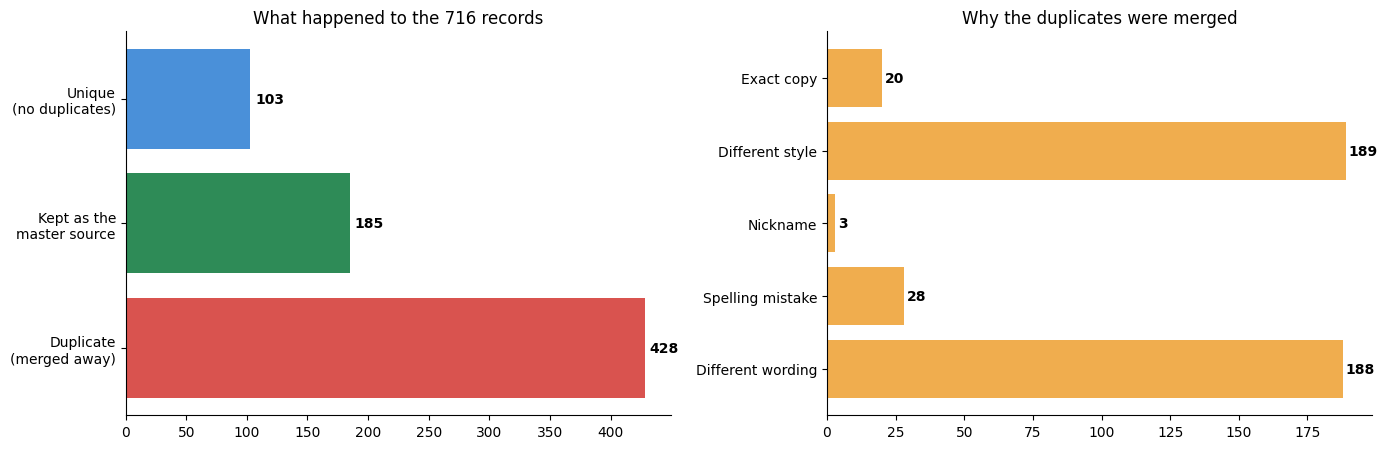


ONE PRODUCT'S JOURNEY: PROD-0157
BEFORE: 7 raw rows


source,product_name,company,size,category,price
Supplier,SENSODYNE REPAIR & PROTECT TOOTHPASTE 75 ML,haleon plc,75,Oral Care,5.49
Shop Counter,sensodyne repair & protect toothpaste,GSK,75 ML,Oral Hygiene,5.49
Accounts,Sensodyne Repair & Protect Toothpaste 0.075L,Haleon,0.075L,Oral Hygiene,"5,49"
Supplier,SENSODYNE REPAIR & PROTECT TOOTHPASTE 75ML,GSK Consumer Healthcare,75ml,Dental,5.61
Shop Counter,sensodyne repair toothpaste,Haleon,0.075L,Oral Care,"5,49"
Accounts,Sensodyne Repair & Protect Toothpaste 0.075L,Haleon,0.075L,Oral Hygiene,"5,49"
Website,Sensodyne Repaair and Protect Toothpaste (Authentic),GSK Consumer Healthcare,75 ml,Dental,5.49


AFTER: 1 master record


Field,Value
Product ID,PROD-0157
Product Name,Sensodyne Repair & Protect Toothpaste 75 ml
Company,Haleon
Category,Oral Care
Size,75 ml
Price,5.49
Active,Yes
Records merged,7
Systems,"Accounts, Shop Counter, Supplier, Website"
How sure (%),90



PLEASE CHECK LIST: 99 of 288 products (8 examples)


Product ID,Product Name,Records merged,How sure (%),Why check
PROD-0001,Cadbury Bournville Dark Chocolate Bar 60 g,4,82,not fully sure these belong together; prices differ a lot between systems
PROD-0002,Cadbury Bournville Dark Chocolate Bar 150 g,3,97,prices differ a lot between systems
PROD-0003,Listerine Cool Mint Mouthwash 1000 ml,6,91,prices differ a lot between systems
PROD-0005,Mountain Dew Code Red Soft Drink 500 ml,4,77,not fully sure these belong together
PROD-0006,Similac Sensitive Infant Formula 850 g,5,92,prices differ a lot between systems
PROD-0011,Sprite Lemon-Lime Soft Drink 2000 ml,5,88,prices differ a lot between systems
PROD-0013,Monster Ultra White Energy Drink 473 ml,1,100,size unit was guessed
PROD-0014,Hellmann's Real Mayonnaise 800 g,6,70,not fully sure these belong together; prices differ a lot between systems


In [26]:
# STEP 9 - Results: before vs after
duplicates = id_map[id_map["Role"] == "Duplicate (merged away)"]
no_price_products = int(final_list["Price"].isna().sum())

heading("BEFORE  vs  AFTER")
show(pd.DataFrame([
    ("Number of rows / products",                          len(data),                                  len(final_list)),
    ("Duplicate rows removed",                              "-",                                        f"{len(duplicates)}  ({len(duplicates) / len(data):.0%} of all rows)"),
    ("Different company spellings",                         data["company"].dropna().nunique(),         final_list["Company"].dropna().nunique()),
    ("Different category labels",                           data["category"].dropna().nunique(),        final_list["Category"].dropna().nunique()),
    ("Rows without a usable price  /  products without one", int(clean["price"].isna().sum() + (clean["price"] <= 0).sum()), no_price_products),
    ("Products a human should double-check",                "-",                                        int((final_list["Please check?"] == "Yes").sum())),
], columns=["", "BEFORE (raw data)", "AFTER (master list)"]))

# ---- Why were records merged? -----------------------------------------------------------------------------------
reasons = ["Exact copy of another row", "Same words, written in a different style", "Nickname or short form (coke = coca cola)",
           "Spelling mistake", "Different wording, same product"]
meaning = {"Exact copy of another row": "the same row was entered twice",
           "Same words, written in a different style": "capital letters, spacing, word order, punctuation or size text differ",
           "Nickname or short form (coke = coca cola)": "a known nickname was used",
           "Spelling mistake": "a word is misspelt",
           "Different wording, same product": "a shorter or reworded name (found by name similarity or the AI helper)"}
counts = duplicates["Why merged"].value_counts().reindex(reasons, fill_value=0)
examples = []
for reason in reasons:
    pick_row = duplicates[duplicates["Why merged"] == reason].head(1)
    examples.append(f'"{pick_row["Original name"].iloc[0]}"  ->  "{pick_row["Final product name"].iloc[0]}"' if len(pick_row) else "")
heading("WHY WERE RECORDS MERGED?")
show(pd.DataFrame({"Reason": reasons, "Rows": counts.values, "Share": [f"{c / max(len(duplicates), 1):.0%}" for c in counts.values],
                   "What it means": [meaning[r] for r in reasons], "Example (before -> after)": examples}))

# ---- Two simple charts ------------------------------------------------------------------------------------------------
roles = id_map["Role"].value_counts()
role_order = ["Only record (no duplicates)", "Kept as the master source", "Duplicate (merged away)"]
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4.6))
left.barh(["Unique\n(no duplicates)", "Kept as the\nmaster source", "Duplicate\n(merged away)"], [int(roles.get(r, 0)) for r in role_order],
          color=["#4a90d9", "#2e8b57", "#d9534f"])
for y, r in enumerate(role_order): left.text(int(roles.get(r, 0)) + 4, y, str(int(roles.get(r, 0))), va="center", weight="bold")
left.set_title(f"What happened to the {len(data)} records"); left.invert_yaxis()
short = ["Exact copy", "Different style", "Nickname", "Spelling mistake", "Different wording"]
right.barh(short, counts.values, color="#f0ad4e")
for y, v in enumerate(counts.values): right.text(v + 1, y, str(int(v)), va="center", weight="bold")
right.set_title("Why the duplicates were merged"); right.invert_yaxis()
for axis in (left, right):
    axis.spines["top"].set_visible(False); axis.spines["right"].set_visible(False)
plt.tight_layout(); plt.savefig("chart_results.png", dpi=130); plt.show()

# ---- Follow one product from raw rows to master record ----------------------------------------------------------------
if answer_key is not None:
    ids_of_example = [final_ids[i] for i in np.where(answer_key["real_product_id"].values == example_id)[0]]
    journey_id = Counter(ids_of_example).most_common(1)[0][0]
else:
    journey_id = final_list.sort_values("Records merged").iloc[-1]["Product ID"]
rows_in = clean.index[clean["product_id"] == journey_id]
heading(f"ONE PRODUCT'S JOURNEY: {journey_id}")
print(f"BEFORE: {len(rows_in)} raw rows")
show(data.loc[rows_in, [c for c in ["source", "product_name", "company", "size", "category", "price"] if c in data.columns]].fillna("(blank)"))
print("AFTER: 1 master record")
master_row = final_list[final_list["Product ID"] == journey_id].iloc[0]
values = [f"{v:.2f}" if f == "Price" and pd.notna(v) else str(v) for f, v in master_row.items()]
show(pd.DataFrame({"Field": master_row.index, "Value": values}).query("Field not in ['Original codes']"))

# ---- What should a human check? ------------------------------------------------------------------------------------------
check_list = final_list[final_list["Please check?"] == "Yes"]
heading(f"PLEASE CHECK LIST: {len(check_list)} of {len(final_list)} products (8 examples)")
show(check_list[["Product ID", "Product Name", "Records merged", "How sure (%)", "Why check"]].head(8))

## Step 10: Accuracy check: how many did we get right?

Because we made the data ourselves, we have an **answer key** that says which records really belong together.
Now we can mark our own homework. The scores are explained in plain words:

- **Correct groups**: when we said two records are the same product, how often were we right?
- **Duplicates caught**: of all records that really belong together, how many did we put together?
- **Overall score**: one number that combines both (higher is better, 100% is perfect)

We compare three approaches side by side, so you can see what each step adds.


SCOREBOARD


,No cleanup (every row is a product),Rules + name similarity,Rules + names + AI helper
Products found (the answer key has 306),716,341,288
Correct groups (we were right when we merged),-,82%,78%
Duplicates caught,0%,83%,96%
OVERALL SCORE,-,83%,86%
Products wrongly mixed (2+ real products stuck together),0,22,30
Products wrongly split (one product left in 2+ groups),198,54,15


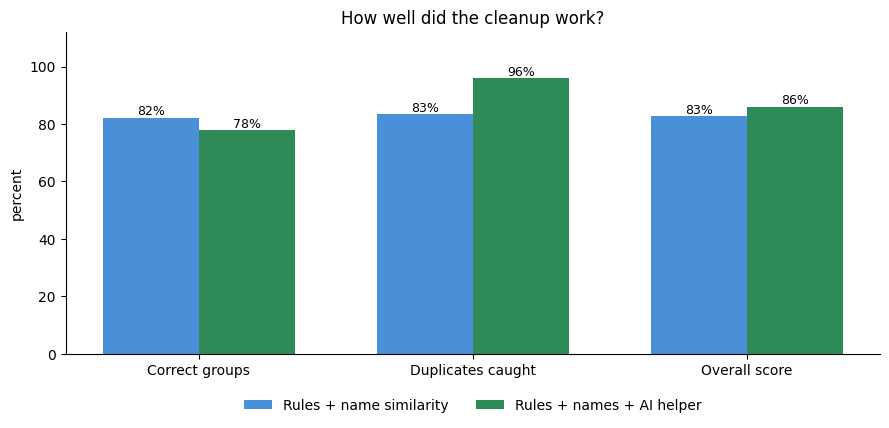


IS THE MASTER LIST ITSELF CORRECT?
We compared the 284 master records with the true values:


Field,Correct
Company,99%
Category,95%
Size,89%
Price (within 10%),93%



EXAMPLES OF MISTAKES (so you know what to expect)
Two different products were stuck together:


Product ID,Names inside this group
PROD-0001,CADBURY BOURNVILLE CHOCOLATE BAR 60 G || Cadbury Bournville Dark Chocolate Bar 60 g || cadbury chocolate bar || cadbury chocolate bar bournville dark 60g
PROD-0009,GARNIER OIL-INFUSED MICELLAR CLEANSING WATER || GARNIER SENSITIVE SKIN MICELLAR CLEANSING WAT || Garnier Oil-Infused Micellar Cleansing Water || garnier sensitive micellar cleansing water
PROD-0014,HELLMANN'S LIGHT MAYONNAISE 800 G || Hellmann's Light Mayonnaise 800 || Hellmann's Real 1.76 lb || Hellmann's Real Mayonnaise || hellman's light mayonnaies 28.2 oz || hellmann's real mayonnaise
PROD-0016,AXE APOLLO BODY SPRAY || AXE BODY SPRAY 150 ML || Axe Apollo Body Spray 5oz || axe apollo body spray


One real product was left in several groups:


Real product,Left in this many groups
Johnson's Lavender Baby Shampoo 200 ml,2
Johnson's Lavender Baby Shampoo 500 ml,2
Vaseline Intensive Care Cocoa Radiant Body Lotion 400 ml,2
Colgate Total Whitening Toothpaste 170 g,2



IN SHORT: from 716 messy records we built 288 products (the answer key says 306). Overall score: 86%.


In [27]:
# STEP 10 - Compare our result with the answer key
if answer_key is None:
    print("Skipped: your own file has no answer key, so there is nothing to compare with.")
else:
    truth = answer_key.set_index("record_id").loc[data["record_id"], "real_product_id"].values

    def pairs_in(numbers):
        return int(sum(n * (n - 1) // 2 for n in numbers))

    def how_accurate(ids):
        table = pd.crosstab(np.array(ids), truth)
        right, ours, real = pairs_in(table.values.ravel()), pairs_in(table.sum(axis=1)), pairs_in(table.sum(axis=0))
        correct, caught = (right / ours if ours else 1.0), right / real
        overall = 2 * correct * caught / max(correct + caught, 1e-9)
        return dict(products=table.shape[0], correct=correct, caught=caught, overall=overall,
                    mixed=int(((table > 0).sum(axis=1) > 1).sum()), split=int(((table.T > 0).sum(axis=1) > 1).sum()), table=table)

    approaches = {"No cleanup (every row is a product)": how_accurate([f"row{i}" for i in range(len(data))]),
                  "Rules + name similarity": how_accurate(ids_without_ai)}
    if ai_ran: approaches["Rules + names + AI helper"] = how_accurate(ids_with_ai)
    last_approach = list(approaches)[-1]

    heading("SCOREBOARD")
    show(pd.DataFrame({
        "": ["Products found (the answer key has " + str(len(set(truth))) + ")", "Correct groups (we were right when we merged)", "Duplicates caught",
             "OVERALL SCORE", "Products wrongly mixed (2+ real products stuck together)", "Products wrongly split (one product left in 2+ groups)"],
        **{name: [r["products"], "-" if name.startswith("No cleanup") else f'{r["correct"]:.0%}', f'{r["caught"]:.0%}',
                  "-" if name.startswith("No cleanup") else f'{r["overall"]:.0%}', r["mixed"], r["split"]] for name, r in approaches.items()}}))

    # chart
    shown = {k: v for k, v in approaches.items() if not k.startswith("No cleanup")}
    fig, axis = plt.subplots(figsize=(9, 4.4))
    width, positions = 0.7 / len(shown), np.arange(3)
    for n, (name, r) in enumerate(shown.items()):
        bars = axis.bar(positions + n * width, [r["correct"] * 100, r["caught"] * 100, r["overall"] * 100], width, label=name, color=["#4a90d9", "#2e8b57"][n])
        for b in bars: axis.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{b.get_height():.0f}%", ha="center", fontsize=9)
    axis.set_xticks(positions + width * (len(shown) - 1) / 2); axis.set_xticklabels(["Correct groups", "Duplicates caught", "Overall score"])
    axis.set_ylim(0, 112); axis.set_ylabel("percent"); axis.set_title("How well did the cleanup work?")
    axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
    axis.spines["top"].set_visible(False); axis.spines["right"].set_visible(False)
    plt.tight_layout(); plt.savefig("chart_accuracy.png", dpi=130); plt.show()

    # is the master list itself right?
    best_table = approaches[last_approach]["table"]
    real_product_info = real_products.set_index("real_product_id")
    right_company = right_category = right_size = right_price = checked = 0
    for product_id, master in final_list.set_index("Product ID").iterrows():
        real_id = best_table.loc[product_id].idxmax()
        if str(real_id).startswith("JUNK"): continue
        real = real_product_info.loc[real_id]
        checked += 1
        right_company  += master["Company"] == real["company"]
        right_category += master["Category"] == real["category"]
        right_size     += master["Size"] == real["size"]
        right_price    += bool(pd.notna(master["Price"]) and abs(master["Price"] - real["price"]) <= 0.10 * real["price"])
    heading("IS THE MASTER LIST ITSELF CORRECT?")
    print(f"We compared the {checked} master records with the true values:")
    show(pd.DataFrame([("Company", right_company / checked), ("Category", right_category / checked), ("Size", right_size / checked),
                       ("Price (within 10%)", right_price / checked)], columns=["Field", "Correct"]).assign(Correct=lambda t: t["Correct"].map("{:.0%}".format)))

    # examples of mistakes
    table = best_table
    mixed_ids = list(table.index[(table > 0).sum(axis=1) > 1])[:4]
    split_ids = list(table.columns[(table > 0).sum(axis=0) > 1])[:4]
    heading("EXAMPLES OF MISTAKES (so you know what to expect)")
    if mixed_ids:
        print("Two different products were stuck together:")
        show(pd.DataFrame({"Product ID": mixed_ids, "Names inside this group": [" || ".join(sorted({data.at[i, 'product_name'].strip()[:45] for i in np.where(np.array(final_ids) == p)[0]}))[:260] for p in mixed_ids]}))
    if split_ids:
        print("One real product was left in several groups:")
        show(pd.DataFrame({"Real product": [real_product_info.at[r, "name"] for r in split_ids],
                           "Left in this many groups": [int((table[r] > 0).sum()) for r in split_ids]}))

    result = approaches[last_approach]
    print(f"\nIN SHORT: from {len(data)} messy records we built {len(final_list)} products (the answer key says {len(set(truth))}). "
          f"Overall score: {result['overall']:.0%}.")

## Step 11: Save and download the files

| File | What it is |
|---|---|
| `final_product_list.csv` | **The master list**: one row per real product |
| `old_to_new_ids.csv` | **The crosswalk**: for each old record, its new Product ID and why it was merged |
| `please_check_list.csv` | Products a person should double-check |
| `chart_results.png`, `chart_accuracy.png` | The charts |
| `products_messy.csv` | The messy input data |

In [28]:
# STEP 11 - Save the files and download them in one zip
import zipfile

final_list.to_csv("final_product_list.csv", index=False)
id_map.to_csv("old_to_new_ids.csv", index=False)
final_list[final_list["Please check?"] == "Yes"].to_csv("please_check_list.csv", index=False)

files_to_save = ["final_product_list.csv", "old_to_new_ids.csv", "please_check_list.csv", "chart_results.png", "chart_accuracy.png", "products_messy.csv"]
with zipfile.ZipFile("results.zip", "w") as bundle:
    for name in files_to_save:
        if os.path.exists(name): bundle.write(name)

print("Saved:")
for name in files_to_save:
    if os.path.exists(name): print("  ", name)

try:
    from google.colab import files
    files.download("results.zip")
except Exception:
    print("\nThe files are in the current folder (results.zip contains all of them).")

Saved:
   final_product_list.csv
   old_to_new_ids.csv
   please_check_list.csv
   chart_results.png
   chart_accuracy.png
   products_messy.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>